# Modelado y evaluación de métricas para predicción de Churn

## Objetivo

El objetivo de este proyecto es entrenar un modelo de clasificación para predecir el abandono de clientes y evaluar su rendimiento mediante diferentes métricas.

Se utiliza Regresión Logística y se analizan las métricas Accuracy, Precision, Recall, F1-Score y Matriz de Confusión.

Además, se analiza la importancia de los falsos negativos en el contexto de la pérdida de clientes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [2]:
df = pd.read_csv("datos/clientes.csv")

print("Cantidad de registros:", len(df))

print("\nPrimeros registros:")
display(df.head())

print("\nValores nulos:")
print(df.isnull().sum())

print("\nDistribucion de la variable objetivo:")
print(df["churn"].value_counts())

Cantidad de registros: 40

Primeros registros:


,cliente_id,edad,antiguedad_meses,gasto_mensual,plan,medio_pago,churn
0,1,25.0,3,30.0,Basico,Tarjeta,1
1,2,45.0,36,90.0,Premium,Transferencia,0
2,3,32.0,12,50.0,Estandar,Tarjeta,0
3,4,22.0,2,25.0,Basico,Efectivo,1
4,5,50.0,48,100.0,Premium,Tarjeta,0



Valores nulos:
cliente_id          0
edad                1
antiguedad_meses    0
gasto_mensual       1
plan                1
medio_pago          1
churn               0
dtype: int64

Distribucion de la variable objetivo:
churn
1    20
0    20
Name: count, dtype: int64


## Preparación de los datos

Se separan las variables predictoras de la variable objetivo.

La columna cliente_id se excluye porque representa un identificador y no una característica predictiva.

Los datos se dividen en un 80% para entrenamiento y un 20% para evaluación, conservando la distribución de las clases mediante estratificación.

In [3]:
# Variables predictoras
X = df.drop(columns=["cliente_id", "churn"])

# Variable objetivo
y = df["churn"]

# Division de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

Registros de entrenamiento: 32
Registros de prueba: 8


In [4]:
columnas_numericas = [
    "edad",
    "antiguedad_meses",
    "gasto_mensual"
]

columnas_categoricas = [
    "plan",
    "medio_pago"
]

# Pipeline numerico
pipeline_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Pipeline categorico
pipeline_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

# Combinar transformaciones
preprocesador = ColumnTransformer([
    ("numericas", pipeline_numerico, columnas_numericas),
    ("categoricas", pipeline_categorico, columnas_categoricas)
])

In [5]:
# Crear pipeline completo
modelo = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Medir tiempo de entrenamiento
inicio = time.perf_counter()

# Entrenar modelo
modelo.fit(X_train, y_train)

tiempo_entrenamiento = time.perf_counter() - inicio

print("Modelo entrenado correctamente.")
print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.6f} segundos")

Modelo entrenado correctamente.
Tiempo de entrenamiento: 0.114566 segundos


## Evaluación del modelo

Se utiliza el conjunto de prueba para evaluar el rendimiento del modelo mediante las siguientes métricas:

- Accuracy: proporción total de predicciones correctas.
- Precision: proporción de clientes correctamente identificados como Churn entre todos los clientes predichos como Churn.
- Recall: proporción de clientes que realmente abandonaron y fueron detectados por el modelo.
- F1-Score: media armónica entre Precision y Recall.

Se considera Churn = 1 como la clase positiva.

In [6]:
# Generar predicciones
y_pred = modelo.predict(X_test)

# Calcular metricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Mostrar resultados
print("METRICAS DEL MODELO")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Reporte completo
print("\nReporte de clasificacion:")
print(classification_report(y_test, y_pred, zero_division=0))

METRICAS DEL MODELO
Accuracy:  0.8750
Precision: 0.8000
Recall:    1.0000
F1-Score:  0.8889

Reporte de clasificacion:
              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.80      1.00      0.89         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8



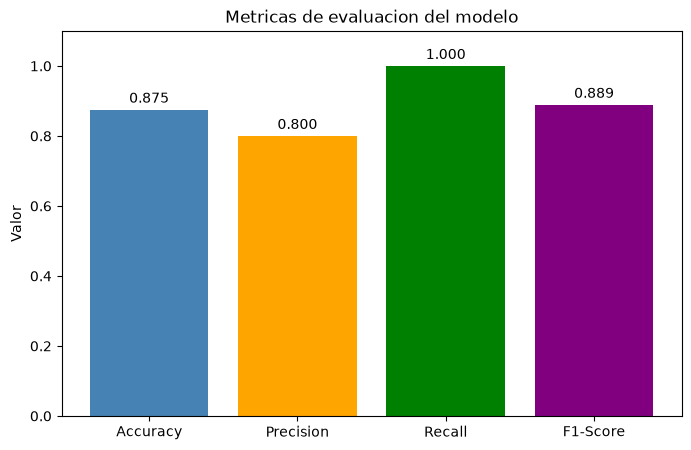

In [7]:
metricas = pd.DataFrame({
    "Metrica": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Valor": [accuracy, precision, recall, f1]
})

plt.figure(figsize=(8, 5))

plt.bar(
    metricas["Metrica"],
    metricas["Valor"],
    color=["steelblue", "orange", "green", "purple"]
)

plt.ylim(0, 1.1)
plt.ylabel("Valor")
plt.title("Metricas de evaluacion del modelo")

for i, valor in enumerate(metricas["Valor"]):
    plt.text(i, valor + 0.02, f"{valor:.3f}", ha="center")

plt.show()

Matriz de confusion:
[[3 1]
 [0 4]]


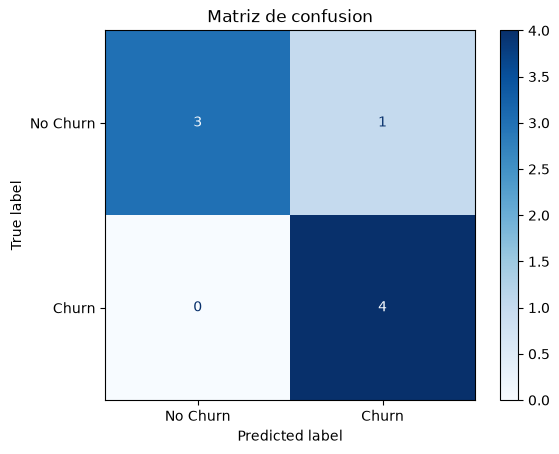

In [8]:
matriz = confusion_matrix(y_test, y_pred)

print("Matriz de confusion:")
print(matriz)

# Visualizacion
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")

plt.title("Matriz de confusion")
plt.show()

## Interpretación de las métricas

En un problema de predicción de Churn, la métrica que se considera prioritaria es Recall para la clase positiva (Churn = 1).

Recall permite medir qué proporción de los clientes que realmente abandonan el servicio son identificados correctamente por el modelo.

Un falso negativo ocurre cuando un cliente que realmente abandonará el servicio es clasificado como un cliente que permanecerá.

Este tipo de error puede generar consecuencias económicas importantes para la empresa:

- Pérdida de ingresos futuros.
- Pérdida de oportunidades para implementar estrategias de retención.
- Incremento de los costos asociados a la adquisición de nuevos clientes.

Por otro lado, un falso positivo ocurre cuando un cliente que permanecerá es clasificado como un cliente con riesgo de abandono.

Este error podría generar costos innecesarios, como ofrecer descuentos o promociones a clientes que no tenían intención de abandonar.

Sin embargo, si el costo de perder un cliente es superior al costo de implementar una acción de retención, resulta conveniente priorizar Recall para reducir la cantidad de falsos negativos.

Accuracy no siempre es suficiente para evaluar un modelo de Churn, especialmente cuando existe un desequilibrio entre las clases.

F1-Score también resulta relevante porque permite evaluar el equilibrio entre Precision y Recall.

La selección definitiva de la métrica debe considerar los costos reales de los errores y los objetivos comerciales de la empresa.

## Conclusión

El modelo de Regresión Logística obtuvo un Accuracy del 87.5%, clasificando correctamente 7 de los 8 clientes del conjunto de prueba.

Los resultados obtenidos fueron:

- Accuracy: 0.8750
- Precision: 0.8000
- Recall: 1.0000
- F1-Score: 0.8889

La matriz de confusión muestra que el modelo identificó correctamente los cuatro clientes que abandonaron el servicio, sin generar falsos negativos.

Se registró un único falso positivo, correspondiente a un cliente que permaneció en el servicio, pero fue clasificado como un posible abandono.

El Recall del 100% resulta especialmente relevante para este problema, ya que permite detectar todos los casos de abandono presentes en el conjunto de prueba y facilita la implementación de estrategias de retención.

El tiempo de entrenamiento del pipeline fue de 0.114566 segundos.

Sin embargo, debido a que el dataset es sintético y contiene solamente 40 registros, estos resultados deben interpretarse con fines educativos y no como una garantía de rendimiento sobre clientes reales.

Como trabajo futuro, se propone utilizar un dataset de mayor tamaño, aplicar validación cruzada y comparar diferentes modelos de clasificación.